## Synthetic Dataset Generation

In [1]:
import numpy as np
import pandas as pd
np.random.seed(42) ##固定随机种子
n = 300
student_id = range(1, n + 1)
ai_hours = np.random.uniform(0, 6, n) ##均匀分布
study_hours = (
    5
    + 0.6 * ai_hours ##正向影响
    - 0.15 * (ai_hours ** 2) ##平方后下降
    + np.random.normal(0, 0.8, n) #平均误差为0，标准差为0.8的正态分布)
study_hours = np.clip(study_hours, 1, 8) #限制学习时间 clip最小为1最大为8
attendance = (
    75
    + np.random.normal(0, 8, n)
    + 3 * study_hours
)
attendance = np.clip(attendance, 60, 100)
critical_thinking = (
    70
    + 4 * ai_hours
    - 1.2 * (ai_hours ** 2)
    + np.random.normal(0, 5, n)
)
critical_thinking = np.clip(critical_thinking, 40, 100)
assignment_score = (
    65
    + 3 * study_hours
    + 1.5 * ai_hours
    + np.random.normal(0, 5, n)
)
assignment_score = np.clip(assignment_score, 40, 100)
# GPA
gpa = (
    1.5
    + 0.012 * assignment_score
    + 0.008 * critical_thinking
    + np.random.normal(0, 0.15, n)
)
gpa = np.clip(gpa, 2.0, 4.0)
major = np.random.choice(
    [
        "Computer Science",
        "Business",
        "Engineering",
        "Education",
        "Data Science"
    ],
    size=n
)
df = pd.DataFrame({
    "student_id": student_id,
    "major": major,
    "ai_hours": np.round(ai_hours, 2),
    "study_hours": np.round(study_hours, 2),
    "attendance": np.round(attendance, 1),
    "assignment_score": np.round(assignment_score, 1),
    "critical_thinking_score": np.round(critical_thinking, 1),
    "gpa": np.round(gpa, 2)
})
print(df.head())

   student_id             major  ai_hours  study_hours  attendance  \
0           1  Computer Science      2.25         5.63        91.4   
1           2         Education      5.70         3.02        74.4   
2           3  Computer Science      4.39         6.46        89.2   
3           4       Engineering      3.59         5.73        92.6   
4           5      Data Science      0.94         3.81        79.5   

   assignment_score  critical_thinking_score   gpa  
0              93.3                     67.9  3.29  
1              84.9                     49.9  2.83  
2              89.7                     64.2  3.07  
3              92.4                     70.1  3.21  
4              83.8                     80.4  3.11  


In [2]:
df.to_csv("student_ai_learning_dataset.csv", index=False)

In [4]:
print(df[["ai_hours", "gpa"]].head(20))

    ai_hours   gpa
0       2.25  3.29
1       5.70  2.83
2       4.39  3.07
3       3.59  3.21
4       0.94  3.11
5       0.94  3.21
6       0.35  3.17
7       5.20  3.16
8       3.61  3.14
9       4.25  3.34
10      0.12  3.02
11      5.82  2.78
12      4.99  3.03
13      1.27  3.00
14      1.09  2.93
15      1.10  3.16
16      1.83  3.41
17      3.15  3.04
18      2.59  3.03
19      1.75  3.23


In [9]:
df.columns

Index(['student_id', 'major', 'ai_hours', 'study_hours', 'attendance',
       'assignment_score', 'critical_thinking_score', 'gpa'],
      dtype='str')

## Figure1：Regression Plot

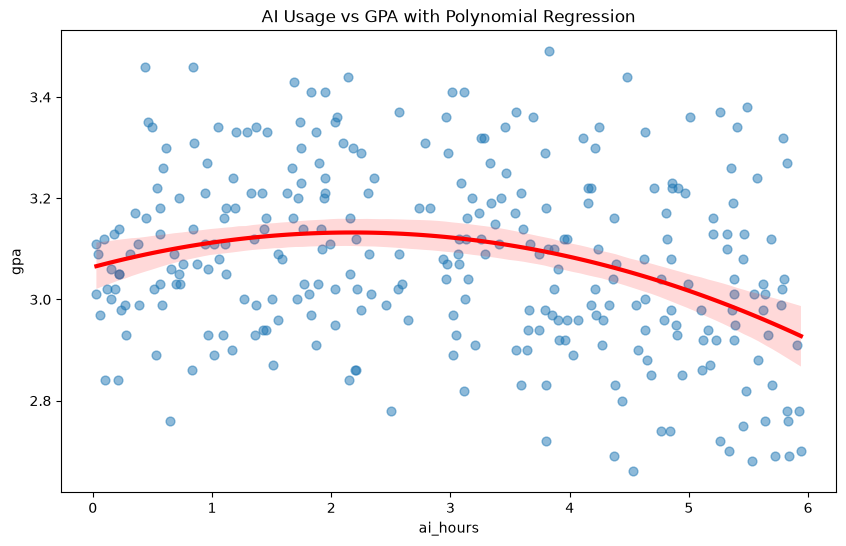

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
df = pd.read_csv("student_ai_learning_dataset.csv")
plt.figure(figsize=(10,6))
sns.regplot(
data=df,
x="ai_hours",
y="gpa",
order=2,
scatter_kws={
"alpha":0.5,##半透明
"s":40 #散点大小
},
line_kws={
"color":"red",
"linewidth":3
}
)
plt.title(
"AI Usage vs GPA with Polynomial Regression"
)
 
plt.show()

## Figure2：Boxplot

C:\Users\liuyi\AppData\Local\Temp\ipykernel_53624\3274175907.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


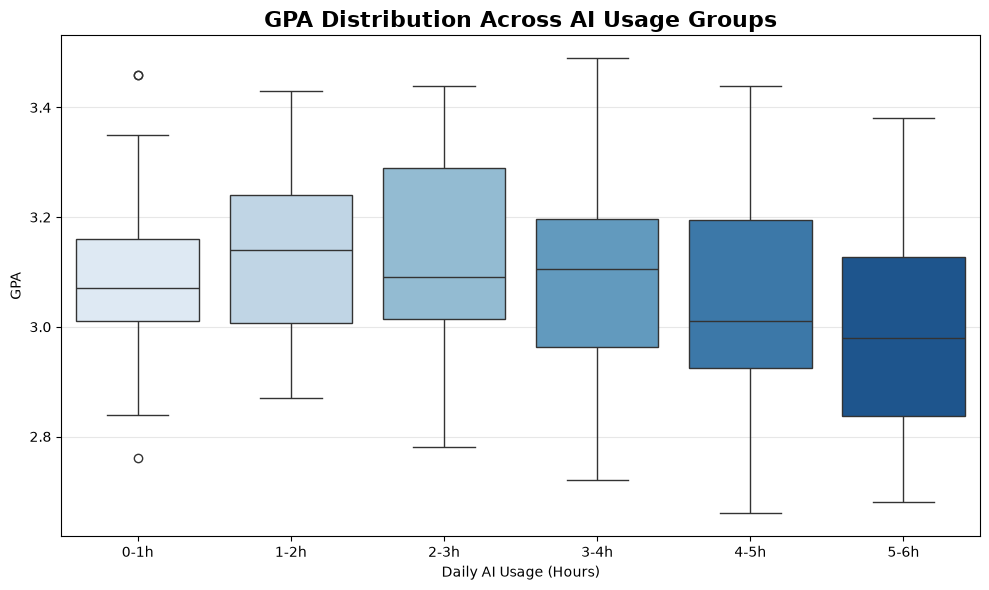

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# 读取数据
df = pd.read_csv("student_ai_learning_dataset.csv")
# 分组
df["AI_Group"] = pd.cut(
df["ai_hours"],
bins=[0,1,2,3,4,5,6],
labels=["0-1h","1-2h","2-3h","3-4h","4-5h","5-6h"])
plt.figure(figsize=(10,6))
sns.boxplot(
data=df,x="AI_Group",y="gpa",palette="Blues")
plt.title("GPA Distribution Across AI Usage Groups",
fontsize=16,fontweight="bold")
plt.xlabel("Daily AI Usage (Hours)")
plt.ylabel("GPA")
plt.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.show()

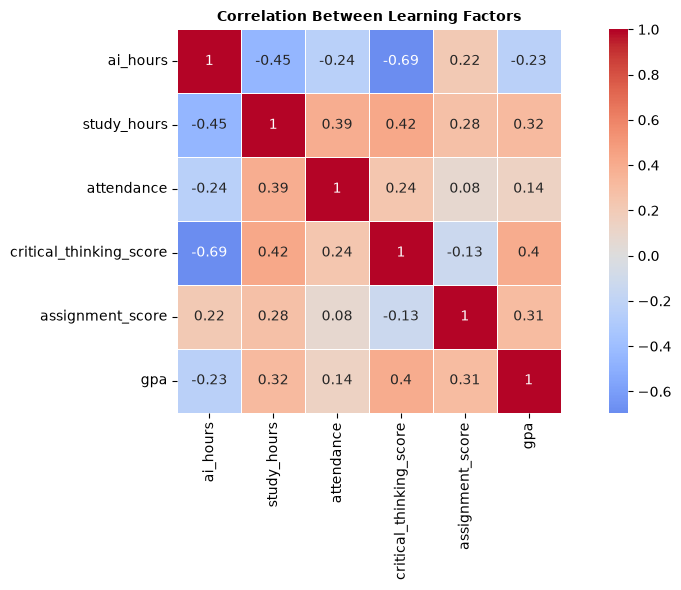

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 读取数据
df = pd.read_csv("student_ai_learning_dataset.csv")
# 选择数值变量
corr = df[
    [
        "ai_hours",
        "study_hours",
        "attendance",
        "critical_thinking_score",
        "assignment_score",
        "gpa"
    ]
].corr()
# 画热力图
plt.figure(figsize=(10,6))
sns.heatmap(
    corr,
    annot=True,      # 显示数字
    cmap="coolwarm", # 蓝-白-红
    center=0,
    square=True,
    linewidths=0.5
)
plt.title(
    "Correlation Between Learning Factors",
    fontsize=10,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

## Figure4：Relationship Between Critical Thinking and GPA

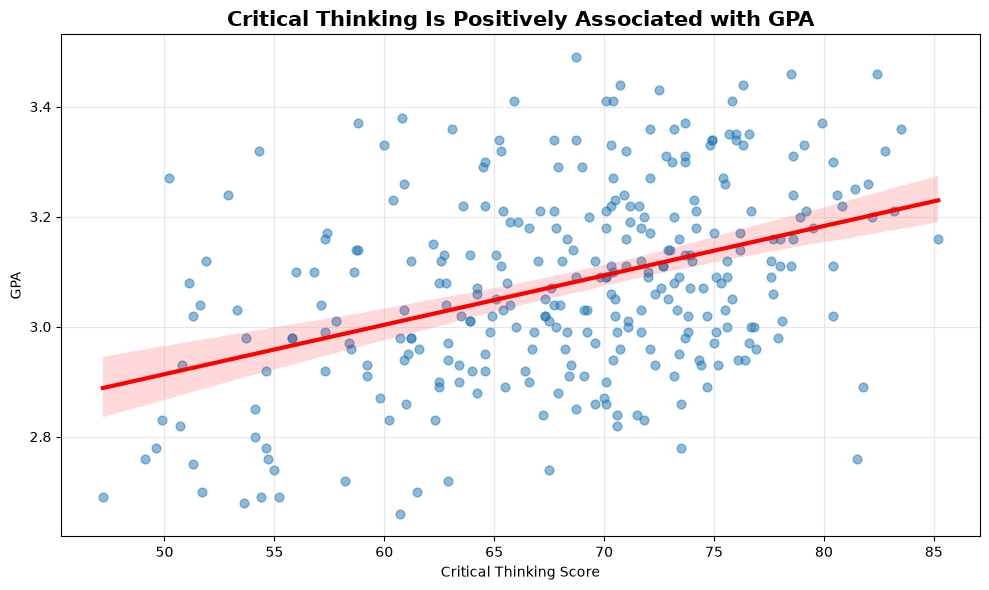

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv("student_ai_learning_dataset.csv")
plt.figure(figsize=(10,6))
sns.regplot(
data=df,
x="critical_thinking_score",
y="gpa",
scatter_kws={
"alpha":0.5,
"s":40
},
line_kws={
"color":"red",
"linewidth":3
}
)
plt.title(
"Critical Thinking Is Positively Associated with GPA",
fontsize=15,
fontweight="bold"
)
plt.xlabel("Critical Thinking Score")
plt.ylabel("GPA")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### The positive association between critical thinking and GPA suggests that critical thinking **may be** a potential mediating factor linking AI usage and academic performance.